# **Indian Interim Union Budget 2023-2024 Analysis**


## 📖 1. Motive / Backstory
The **Union Budget of India** is the most highly anticipated economic event of the year. Delivered by the Hon'ble Finance Minister in Parliament, this comprehensive speech doesn't just allocate funds—it sets the economic narrative, defines the government's priorities, and influences market sentiment for the entire fiscal year.

However, a 30 to 40-page technical speech can be overwhelming to digest manually. While news channels provide summarized highlights, the raw, authentic tone and granular focus of the government often get lost in media interpretation. As data enthusiasts, we can leverage **Natural Language Processing (NLP)** to bypass the noise, directly analyze the authentic Parliamentary transcript, and let the data reveal the true priorities of the budget.

---

## 🏛️ 2. Understanding the Context: The First Budget in *Amrit Kaal* (2023–24)
Unlike an election year with interim arrangements, **Budget 2023–24 was a full-fledged annual budget** presented on **February 1, 2023**. It held immense historic and strategic importance as the government termed it the **"First Budget of Amrit Kaal"**, establishing the economic foundation for India’s journey toward its centenary of independence (*India @ 100*).

### The Strategic Blueprint: *Saptarishi* (7 Priorities)
Rather than isolated allocations, the 2023–24 speech was structured around **seven guiding pillars**, acting as the celestial *Saptarishi* guiding the economy:

1. **Inclusive Development:** Farmers, women, youth, and marginalized communities.
2. **Reaching the Last Mile:** Aspirational districts, tribal welfare, and rural sanitation.
3. **Infrastructure & Investment:** Unprecedented surge in capital expenditure ($\approx$ ₹10 Lakh Crore / 3.3% of GDP).
4. **Unleashing the Potential:** Ease of doing business, trust-based governance, and digital public infrastructure.
5. **Green Growth:** National Green Hydrogen Mission, energy transition, and net-zero goals.
6. **Youth Power (*Amrit Peedhi*):** National Education Policy, PMKVY 4.0, and skill development for Industry 4.0.
7. **Financial Sector:** Credit guarantee schemes for MSMEs and revamped financial regulations.

### Key Contextual Highlights at a Glance

| Strategic Pillar | Core Focus Area (Budget 2023–24) |
| :--- | :--- |
| **National Theme** | *Amrit Kaal* Vision: Tech-driven, knowledge-based economy with robust public finances |
| **Macro Focus** | Massive CapEx push to crowd-in private investments and counter global economic headwinds |
| **Tax Reforms** | Comprehensive revamp of the **New Personal Income Tax Regime** (tax rebate limit raised to ₹7 Lakh) |
| **Fiscal Prudence** | Glide path target to bring the fiscal deficit below 4.5% by FY 2025–26 |

---

## 🎯 3. Problem Statement
**Objective:** To systematically analyze the **Union Budget Speech 2023–24** using Natural Language Processing (NLP) to extract underlying sentiments, dominant themes, and quantitative sector priorities directly from the official transcript.

**Specific Goals of this Project:**
1. **Automated Extraction:** Programmatically fetch and parse the authentic 2023–24 budget speech document directly from the official India Budget portal using `requests` and `pypdf`.
2. **Text Processing & Cleaning:** Standardize raw speech text by eliminating stop words, parliamentary jargon (*Madam Speaker*, *Hon'ble*, etc.), financial metrics (*crores*, *lakhs*), and punctuation to build a clean analytical corpus.
3. **Thematic & Sectoral EDA:** Identify high-frequency terms, unigrams, and bigrams mapped to the *Saptarishi* priorities (Infrastructure, Agriculture, Digital Economy, Green Energy, Health, and MSMEs) via custom WordClouds and Seaborn distributions.
4. **Sentiment & Polarity Trajectory:** Track sentence/paragraph-level polarity scores across the duration of the speech—evaluating whether the tone transitions from optimistic macroeconomic vision to balanced fiscal allocations and tax reforms.

### **Library Importation**

In [1]:
import numpy as np
import pandas as pd
import requests
import os
import pypdf
import seaborn as sns
import nltk
import string
import ollama
import matplotlib.pyplot as plt
from google import genai
from google.genai import types
from docx import Document
from wordcloud import WordCloud
from textblob import TextBlob
from nltk.util import ngrams
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from collections import Counter
from scipy import stats
from dotenv import load_dotenv
from groq import Groq

import warnings
warnings.filterwarnings("ignore")


In [2]:
import nltk
import ssl


try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

nltk.download('punkt')
nltk.download('punkt_tab') 
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\AVIRAL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\AVIRAL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\AVIRAL\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [3]:
url = "https://www.indiabudget.gov.in/doc/bspeech/bs2023_24.pdf"
file_name = "Budget_Speech_2023-24.pdf"
headers = {"User-Agent": "Edge/120.0"}

res = requests.get(url, headers=headers)
if res.status_code != 200:
    res = requests.get("https://www.indiabudget.gov.in/budget2023-24/doc/bspeech/bs2023_24.pdf", headers=headers)

if res.status_code == 200:
    with open(file_name, "wb") as f:
        f.write(res.content)
    print("Downloaded.")
else:
    print(f"Fetch failed: {res.status_code}")

li = []
if os.path.exists(file_name):
    reader = pypdf.PdfReader(file_name)
    for page in reader.pages:
        text = page.extract_text()
        if text:
            li.extend([p.strip() for p in text.split('\n') if len(p.strip()) > 30])
    print(f"Extracted {len(li)} paragraphs.")
else:
    print("File missing.")

Downloaded.
Extracted 1247 paragraphs.


In [4]:
import pypdf

# PDF read karne ke liye
reader = pypdf.PdfReader(file_name)
li = []

for page in reader.pages:
    text = page.extract_text()
    if text:
        # Paragraphs ko break karke clean text nikaalna
        for p in text.split("\n"):
            p = p.strip()
            if len(p) > 25:  # chhote headers/page numbers filter karne ke liye
                li.append(p)

print(f"\n✅ Extraction Complete! The speech contains {len(li)} paragraphs.")
print("\n--- Initial Look at Data ---")
print(li[:2])


✅ Extraction Complete! The speech contains 1307 paragraphs.

--- Initial Look at Data ---
['\uf0b7 Achievements since 2014: Leaving no one behind 2', '\uf0b7 Vision for Amrit Kaal – an empowered and inclusive economy 3']


In [8]:
stop_words = set(stopwords.words("english"))
budget_fillers = {
    'madam', 'speaker', 'sir', 'honble', 'hon', 'ble', 'house', 'parliament', 
    'members', 'member', 'table', 'present', 'speech', 'beg', 'leave',

    'crore', 'crores', 'lakh', 'lakhs', 'rupee', 'rupees', 'rs', 'inr', 
    'per', 'cent', 'percent', 'percentage', 'rate', 'rates', 'amount', 
    'estimated', 'estimates', 'total', 'approx', 'number', 'level',

    'propose', 'proposed', 'proposes', 'proposing', 'proposal', 'proposals',
    'provide', 'provided', 'provides', 'providing', 'provision', 'provisions',
    'announce', 'announced', 'announces', 'announcing',
    'setup', 'launched', 'launch', 'initiated', 'facilitate', 'facilitating',
    'enhance', 'enhancing', 'undertake', 'undertaken', 'continue', 'continued',
    'assist', 'assistance', 'support', 'enable', 'implement', 'implemented',

    'act', 'section', 'sub', 'clause', 'clauses', 'subsection', 'amend', 
    'amended', 'amendment', 'amendments', 'schedule', 'notification', 
    'notified', 'prescribed', 'applicable', 'regime', 'exemption', 
    'deduction', 'assessment', 'specified', 'respect', 'matter', 'regard',

    'government', 'gov', 'budget', 'union', 'central', 'state', 'states',
    'year', 'years', 'financial', 'fy', 'period', 'annual', 'current', 
    'next', 'past', 'time', 'day', 'month', 'months', 'phase',
    'also', 'well', 'like', 'part', 'para', 'annexure', 'various', 
    'across', 'including', 'included', 'basis', 'terms', 'manner', 'measures', "certain", "new"
}

custom_stop_words = stop_words.union(budget_fillers)

In [9]:
def clean_text(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = ''.join([i for i in text if not i.isdigit()])
    

    y = word_tokenize(text)

    cleaned_text = [w for w in y if w not in custom_stop_words and len(w) > 2]

    return " ".join(cleaned_text)


clean_paras = [clean_text(q) for q in li]

full_cleaned_Speech = " ".join(clean_paras)


print("Data Cleaning Completed")

print("Cleaned preview:", clean_paras[10][:100],"....")

Data Cleaning Completed
Cleaned preview: relating indirect taxes ....


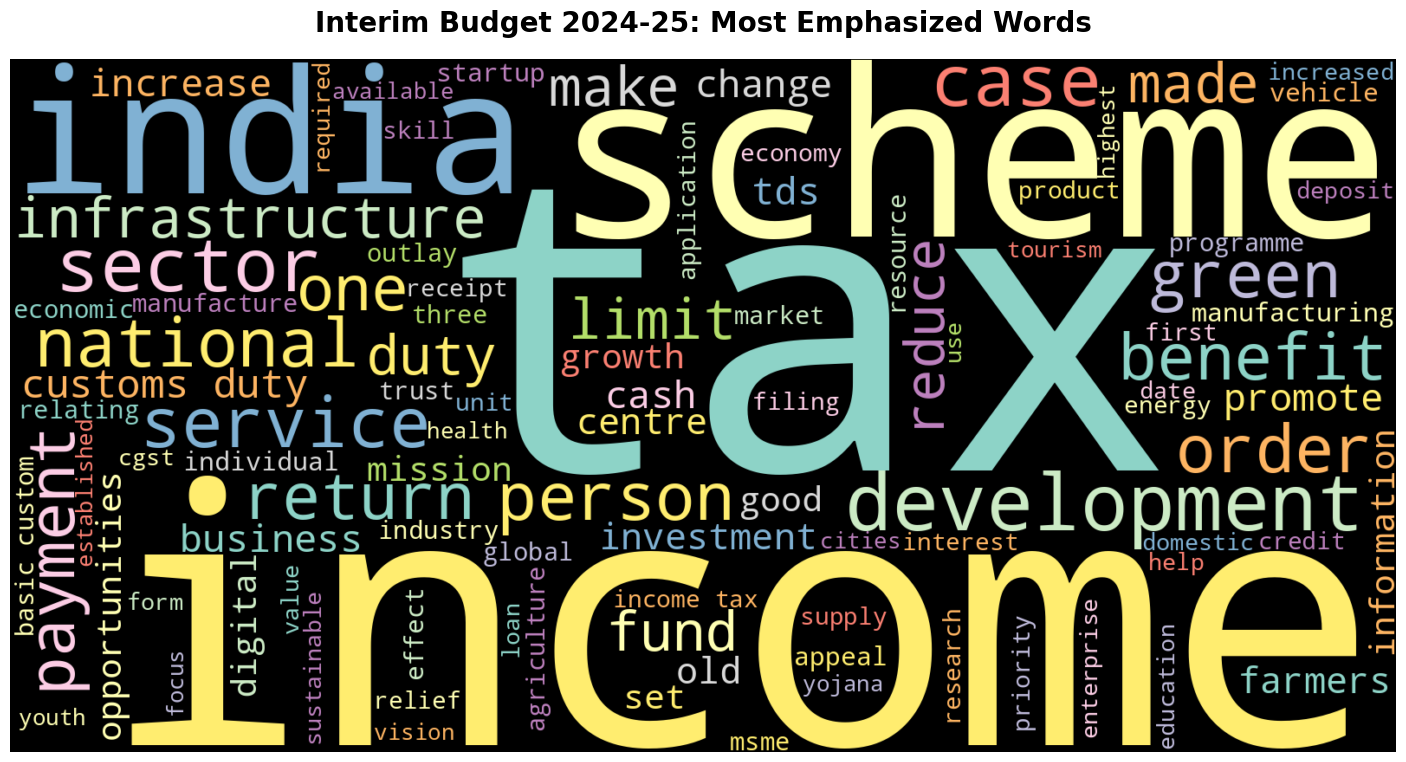

In [10]:
plt.figure(figsize=(18,9))
cloud = WordCloud(width=1600,height=800,background_color="black", colormap='Set3', max_words=101).generate(full_cleaned_Speech)
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Interim Budget 2024-25: Most Emphasized Words", fontsize=20, fontweight='bold', pad=20)
plt.show()

In [11]:
ls = full_cleaned_Speech.split()
cnt = Counter(ls)
top10 = cnt.most_common(10)

df = pd.DataFrame(top10, columns=['Word', 'Frequency'])
df

,Word,Frequency
0,tax,76
1,income,53
2,development,36
3,duty,30
4,infrastructure,28
5,india,28
6,customs,27
7,capital,24
8,shall,23
9,sector,21


In [12]:
bigrams = ngrams(ls,2)
bigrams_freq = Counter(bigrams)


top10_bigrams = bigrams_freq.most_common(10)
bigrams_data = {"Bigrams" : [f"{q[0][0]} {q[0][1]}" for q in top10_bigrams],
                "Count" : [q[1] for q in top10_bigrams]}


df_bigrams = pd.DataFrame(bigrams_data)
df_bigrams

,Bigrams,Count
0,customs duty,15
1,basic customs,10
2,income tax,10
3,amrit kaal,7
4,public infrastructure,6
5,primary agricultural,6
6,capital expenditure,6
7,urban infrastructure,6
8,fiscal deficit,6
9,capital gains,6


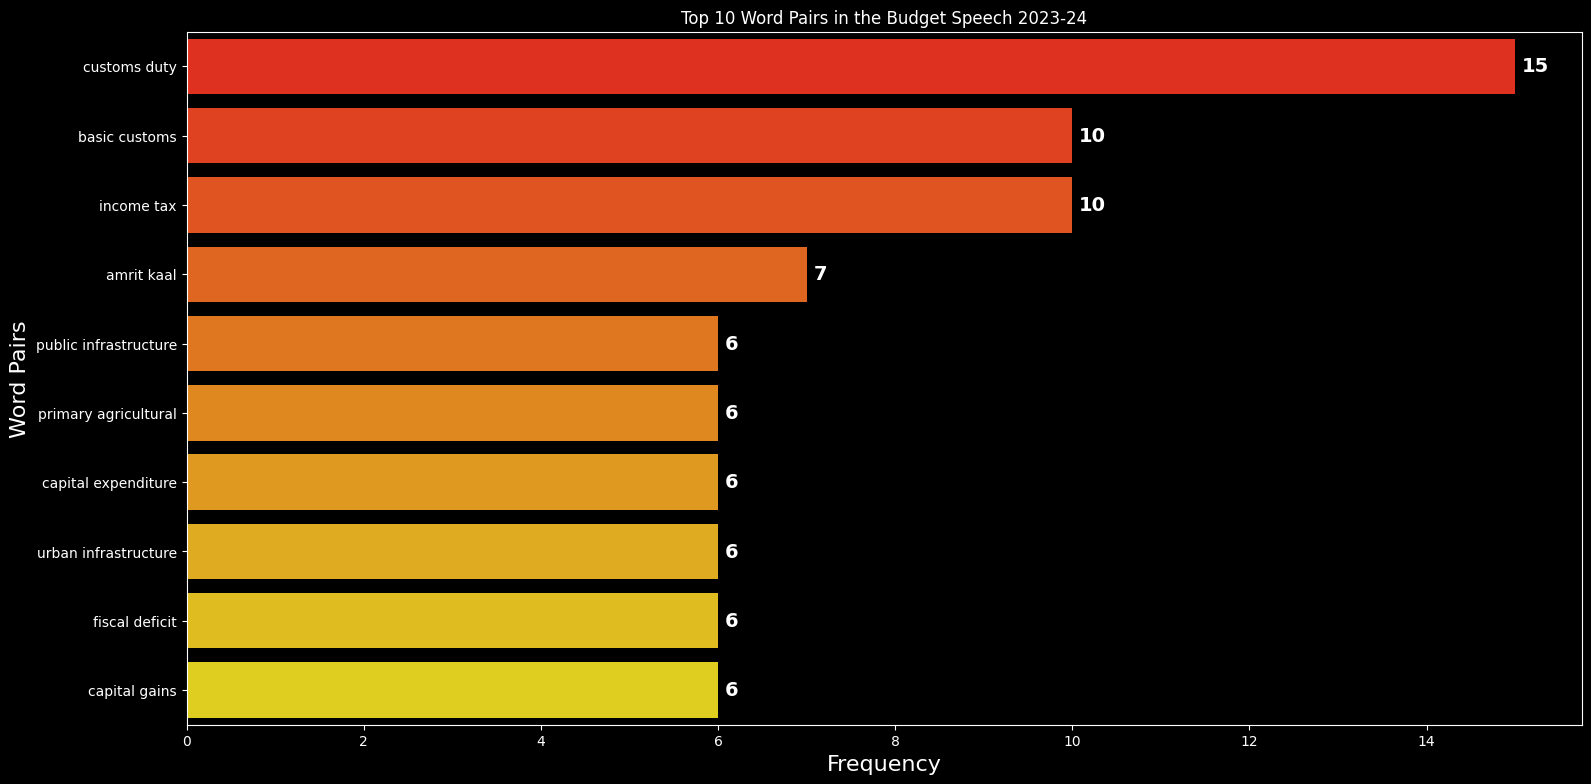

In [13]:
plt.style.use("dark_background") 

plt.figure(figsize=(18,9))
bar = sns.barplot(x="Count", y="Bigrams", data=df_bigrams, palette="autumn")

for i in bar.containers:

    bar.bar_label(i, padding=5, color='white', fontsize=14, fontweight='bold')

plt.title('Top 10 Word Pairs in the Budget Speech 2023-24')
plt.xlabel("Frequency", fontsize=16)
plt.ylabel("Word Pairs", fontsize=16)
plt.show()

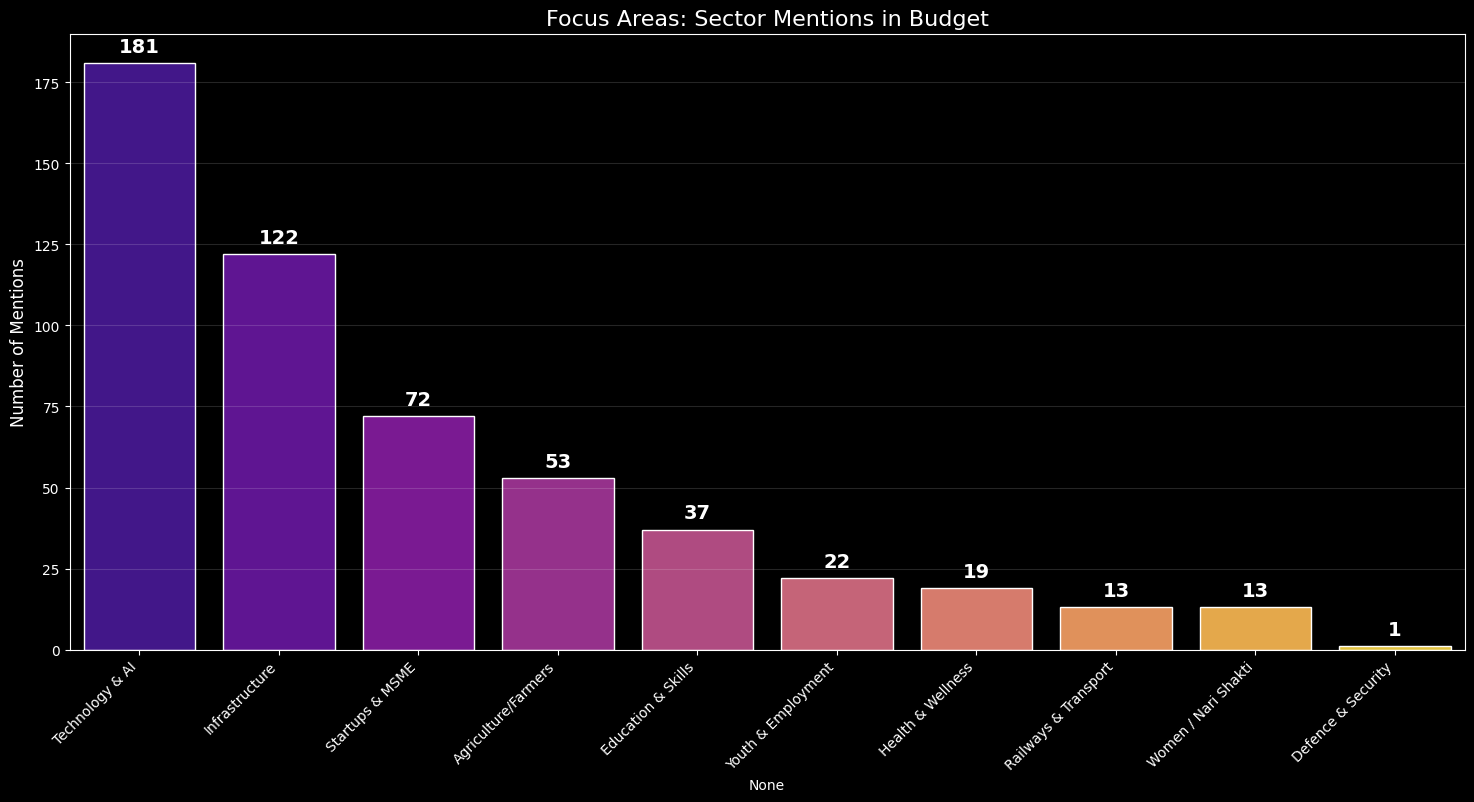

In [14]:
sec = {
    'Agriculture/Farmers': ['agriculture', 'farmer', 'farmers', 'kisan', 'crop', 'crops', 'rural', 'irrigation'],
    'Education & Skills': ['education', 'school', 'schools', 'college', 'university', 'students', 'learning', 'skill', 'skills'],
    'Health & Wellness': ['health', 'hospital', 'hospitals', 'medical', 'disease', 'vaccine', 'nutrition', 'ayushman'],
    'Railways & Transport': ['rail', 'railway', 'railways', 'train', 'trains', 'vande bharat', 'station', 'metro'],
    'Technology & AI': ['technology', 'digital', 'tech', 'ai', 'innovation', 'artificial intelligence', 'research'],
    'Defence & Security': ['defence', 'military', 'army', 'navy', 'airforce', 'armed forces', 'border'],
    'Women / Nari Shakti': ['women', 'woman', 'girl', 'girls', 'nari', 'shakti', 'mahila', 'matru'],
    'Youth & Employment': ['youth', 'young', 'employment', 'jobs', 'job', 'rozgar', 'career'],
    'Startups & MSME': ['startup', 'startups', 'msme', 'msmes', 'entrepreneur', 'entrepreneurship', 'business', 'businesses'],
    'Infrastructure': ['infrastructure', 'infra', 'roads', 'highway', 'highways', 'bridge', 'bridges', 'port', 'ports', 'aviation']
}

dict = {}

for sector_name, word_list in sec.items():
    total = 0
    for word in word_list:
        total += full_cleaned_Speech.count(word)
    dict[sector_name] = total

df_sec = pd.Series(dict).sort_values(ascending=False)

plt.figure(figsize=(18,8))
ax = sns.barplot(x=df_sec.index, y=df_sec.values, palette='plasma', edgecolor="white")

for container in ax.containers:
    ax.bar_label(container, padding=5, color='white', fontsize=14, fontweight='bold')

plt.title("Focus Areas: Sector Mentions in Budget", fontsize=16)
plt.ylabel("Number of Mentions", fontsize=12)
plt.xticks(rotation=45, ha='right') 
plt.grid(axis='y', alpha=0.15)
plt.style.use('dark_background')
plt.show()

In [15]:
lt = []

for i in clean_paras:
    if len(i) > 10:
        blob = TextBlob(i)

        lt.append(blob.sentiment.polarity)


df_sentiments = pd.DataFrame(lt, columns=['Polarity'])

avg_sentiment = df_sentiments["Polarity"].mean()




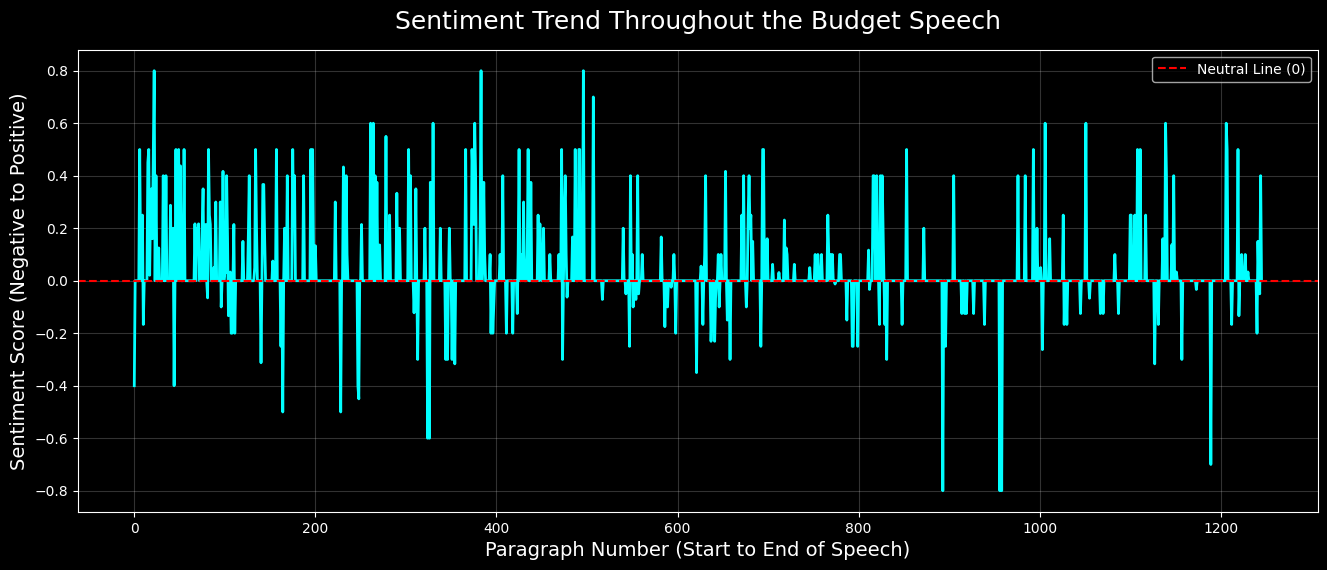

Sentiment Analysis Results
---------------------------------------------
Overall Tone: NEUTRAL (Factual/Balanced) | Score: 0.032


In [16]:
plt.figure(figsize=(16, 6))
plt.plot(df_sentiments['Polarity'], color='cyan', linewidth=2)
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5, label='Neutral Line (0)')
plt.title("Sentiment Trend Throughout the Budget Speech", fontsize=18, pad=15)
plt.xlabel("Paragraph Number (Start to End of Speech)", fontsize=14)
plt.ylabel("Sentiment Score (Negative to Positive)", fontsize=14)
plt.legend()
plt.grid(alpha=0.2)
plt.style.use('dark_background')
plt.show()


print('Sentiment Analysis Results')
print("-"*45)
if avg_sentiment > 0.05:
        print(f"Overall Tone: POSITIVE (Optimistic & Growth-oriented) | Score: {avg_sentiment:.3f}")
elif avg_sentiment < -0.05:
    print(f"Overall Tone: CAUTIOUS / NEGATIVE | Score: {avg_sentiment:.3f}")
else:
    print(f"Overall Tone: NEUTRAL (Factual/Balanced) | Score: {avg_sentiment:.3f}")

In [17]:
desc_stats = df_sentiments[['Polarity']].describe().T.round(3)

desc_stats.columns = ['Total Paragraphs', 'Average (Mean)', 'Std Dev', 'Minimum', '25%', 'Median', '75%', 'Maximum']
desc_stats.index = ['Sentiment Tone']

desc_stats

,Total Paragraphs,Average (Mean),Std Dev,Minimum,25%,Median,75%,Maximum
Sentiment Tone,1246.0,0.032,0.154,-0.8,0.0,0.0,0.0,0.8


In [18]:
mp = len(df_sentiments)//2

hf1 = df_sentiments['Polarity'][:mp]
hf2 = df_sentiments['Polarity'][mp:]

print(f"First Half Average Sentiment: {hf1.mean():.3f}")
print(f"Second Half Average Sentiment: {hf2.mean():.3f}")


t_stat, pval = stats.ttest_ind(hf1, hf2)

print(f'''T-Test hypothesis 
Test Statistic Value = {t_stat:.4f}
P Value = {pval:.4f}''')


if pval < 0.05:

    print("\nConclusion: P-value is lower 0.05 threshold.")
    print("This refers to that we have a significant difference between tone of first half and second half")
else:
    print("\nConclusion: P-value is higher than 0.05 threshold.")
    print("This refers to that we don't have a significant difference between tone of first half and second half")



First Half Average Sentiment: 0.049
Second Half Average Sentiment: 0.014
T-Test hypothesis 
Test Statistic Value = 4.0165
P Value = 0.0001

Conclusion: P-value is lower 0.05 threshold.
This refers to that we have a significant difference between tone of first half and second half


In [19]:
from IPython.display import display, Markdown

def model_eval(model, text_data):

    print(f"{model.upper()} is analyzing the budget......")

    # Aapka exact same prompt, maine isme 1 word bhi change nahi kiya hai
    prompt =f"""You are a highly skilled Economic Analyst and Data Scientist analyzing the Indian Union Budget Speech. 

Based strictly on the provided budget speech text, I need a comprehensive, structured, and highly detailed analysis broken down into the following three specific sections:

### 1. Sector-Wise Allocations & Focus
Provide a detailed breakdown of what specific announcements, funds, or policies were made for the following 10 sectors. (If a sector was not significantly mentioned, state "Limited mentions"):
- Agriculture & Farmers
- Education & Skills
- Health & Wellness
- Railways & Transport
- Technology & AI
- Defence & Security
- Women / Nari Shakti
- Youth & Employment
- Startups & MSME
- Infrastructure

### 2. The 'Rupee Comes From' Analysis (Revenue)
Explain the government's revenue model. If the government earns 100 Rupees, break down exactly where this money is coming from (e.g., Corporate Tax, Income Tax, GST, Borrowings, Non-tax revenue, etc.). Provide the exact percentages or paise breakdown if mentioned in the text.

### 3. The 'Rupee Goes To' Analysis (Expenditure)
Explain the government's expenditure model. If the government spends 100 Rupees, break down exactly where it is going (e.g., Interest Payments, Defence, Subsidies, State shares, Pensions, Central Sector Schemes, etc.). Provide the exact percentages or paise breakdown if mentioned in the text.

Format your response clearly using Markdown, bold text for key numbers, and bullet points. Do not hallucinate; use only the data present in the text provided below.

---
BUDGET SPEECH TEXT:
{text_data}
"""
    
    try:
        response = ollama.chat(model=model, messages=[{'role' : "user", "content" :prompt}])
        print(f'\n {model.upper()} Budget Analysis')
        print("=" * 60)
        
        # YAHAN CHANGE KIYA HAI: print() hata diya, aur display(Markdown()) laga diya
        # Issey Output scrollable nahi aayega, balki professional formatted aayega
        display(Markdown(response['message']['content']))
        
        print("=" * 60 + "\n")

    except Exception as e:
        print("ERROR with Ollama Models therefore Kindly Check Again..............")

In [20]:
budget_doc = " ".join(li)
model_eval('phi3', budget_doc )

PHI3 is analyzing the budget......

 PHI3 Budget Analysis


The document appears to be a comprehensive budget proposal addressing a multitude of issues related to legislative and tax changes, particularly focusing on indirect taxes, customs duties, and central excise. It proposes amendments to various acts and sections to improve tax implementation, refine tax rates, extend benefits, and introduce new compliance requirements. The document also includes significant changes to the Customs and GST laws, aimed at refining tax rates for various items and services, and enhancing the ease of doing business. Furthermore, it proposes changes in the Central Excise Duty to promote green fuel, and adjusts the Customs Duty structure to boost domestic manufacturing, reduce input costs, and support exports. The document seems to be drafting amendments to facilitate e-commerce, especially for micro enterprises, and aligns certain classifications with those of the Reserve Bank of India. It also addresses matters like input tax credit for CSR, sharing of information, online database access, place of supply, interest on delayed tax payments, and rules for appeals and penalties under the Benami Act. The document also suggests decriminalizing certain acts of omission by liquidators, extending tax exemptions, and setting conditions for SEZ units and export incomes. Amendments in the Customs Act and the GST Act are proposed to streamline procedures and facilitate businesses. The changes in Customs Duty rates are aimed at promoting the manufacturing of certain products and substances, while the changes in the Central Excise Duty are designed to support green fuel and specific sectors like gems and jewelry. There are a few minor changes of minor nature proposed as well.

In [21]:
budget_doc = " ".join(li)
model_eval('llama3.1', budget_doc )

LLAMA3.1 is analyzing the budget......

 LLAMA3.1 Budget Analysis


This text appears to be an excerpt from the Explanatory Memorandum to the Budget Speech 2023-24, detailing various amendments and proposals to the Income-tax Act, 1961, as well as the Customs Act, 1962, and the Goods and Services Tax (GST) laws. The text outlines several key changes and proposals, including:

**Income-tax Act, 1961**

1.  **Interest on borrowed capital**: The cost of acquisition or improvement shall not include the amount of interest claimed.
2.  **Intangible assets and rights**: The cost of acquisition of intangible assets or rights for which no consideration has been paid shall be defined as NIL.
3.  **Rectification of orders**: The time-limit for amending an order by the Interim Board of Settlement shall be extended to 30.09.2023.
4.  **Appeals against penalty orders**: Appeal against penalty orders passed by Commissioner (Appeals) under certain sections of the Act shall be allowed.
5.  **Tax on borrowed capital**: The interest on borrowed capital for acquiring or improving a property can be claimed as deduction from income.

**Customs Act, 1962**

1.  **Customs duty exemptions**: Section 25 (4A) is being amended to exclude certain categories of conditional customs duty exemptions from the validity period of two years.
2.  **Anti-Dumping Duty (ADD), Countervailing Duty (CVD), and Safeguard Measures**: Sections 9, 9A, 9C of the Customs Tariff Act are being amended to clarify the intent and scope of these provisions.
3.  **First Schedule to the Customs Tariff Act, 1975**: The First Schedule is being amended to increase the rates on certain tariff items and modify the rates on certain other tariff items.
4.  **Second Schedule to the Customs Tariff Act**: The Second Schedule (Export Tariff) is being amended to align the entries under heading 1202 with that of the First Schedule (Import Tariff).

**Goods and Services Tax (GST) laws**

1.  **Amendments in section 132 and section 138 of CGST Act**: The minimum threshold of tax amount for launching prosecution under GST is being raised from ₹ 1 crore to ₹ 2 crore.
2.  **Decriminalization of certain offences**: Certain offences specified under clause (g), (j) and (k) of sub-section (1) of section 132 of CGST Act are being decriminalized.
3.  **Facilitate e-commerce for micro enterprises**: Amendments are being made in section 10 and section 122 of the CGST Act to enable unregistered suppliers and composition taxpayers to make intra-state supply of goods through E-Commerce Operators (ECOs).
4.  **Sharing of information**: A new section 158A is being inserted to enable sharing of the information furnished by the registered person in his return or application of registration or statement of outward supplies.

**Customs Duty Rate Changes**

1.  **Reduction in basic customs duty**: Basic customs duty is being reduced on certain items to reduce input costs, deepen value addition, to promote export competitiveness, correct inverted duty structure so as to boost domestic manufacturing, etc.
2.  **Increase in Customs duty**: Customs duty is being increased on certain items, including vinyl chloride monomer and silver (including silver plated with gold or platinum).

**Central Excise Duty Changes**

1.  **NCCD Duty rate**: The NCCD duty rate is being changed on cigarettes, with effect from 02.02.2023.
2.  **Other changes in Central Excise**: Central excise duty exemption is being provided to blended Compressed Natural Gas from so much of the amount as is equal to the GST paid on Bio Gas/Compressed Bio Gas contained in the blended Compressed Natural Gas.

These are just some of the key changes and proposals outlined in the Explanatory Memorandum. The text is quite lengthy and detailed, and it is recommended that the Explanatory Memorandum and other relevant budget documents be referred to for a comprehensive understanding of the budget proposals.

In [22]:
budget_doc = " ".join(li)
model_eval('qwen2', budget_doc )

QWEN2 is analyzing the budget......

 QWEN2 Budget Analysis


The Indian government's budget proposals for the financial year 2023-2024 aim to introduce several key changes in the income tax and customs laws to promote domestic manufacturing, enhance export competitiveness, and reduce inverted duty structures. Some of the major changes include:

1. **Income Tax Reforms**: 
   - New tax slabs are proposed to replace the existing ones, offering a simplified structure for taxpayers.
   - A new tax regime with lower tax rates is introduced for individuals with incomes exceeding certain thresholds, aiming to provide relief for higher income taxpayers.

2. **Customs Duty Rate Changes**: 
   - Duty rates are reduced on certain inputs for manufacturing, such as fish meal and mineral/vitamin premixes for aquafeed, to promote domestic manufacturing and export competitiveness.
   - Duty rates are increased on certain luxury goods and vehicles to discourage imports.

3. **GST Revisions**:  
   - The minimum threshold for initiating GST prosecution is raised to boost enforcement efforts.
   - Compounding amounts for GST liabilities are reduced to simplify compliance for small businesses.

4. **Corporate Social Responsibility**:  
   - Input tax credit for expenses related to CSR activities is disallowed to align with tax policies and deter misuse.

5. **E-commerce Facilitation**: 
   - Unregistered suppliers and composition taxpayers can now make intra-state sales through e-commerce platforms, subject to specific conditions.

6. **Customs Duty Exemptions**: 
   - Certain conditional exemptions from customs duties are excluded from the validity period of two years, aligning with longer-term policies and agreements.

7. **GST Tax Exemption**: 
   - Specified Undertaking of Unit Trust of India (SUUTI) is granted a tax exemption extension till September 30, 2023.

8. **Legal Reforms**: 
   - Decriminalization of certain acts under customs laws is proposed, reducing the scope for punitive measures against offenders.

These reforms aim to streamline tax policies, encourage domestic production, and simplify compliance norms for businesses while ensuring effective enforcement of tax laws.

In [ ]:
import os
from google import genai
from google.genai import types
from IPython.display import display, Markdown

client = genai.Client(api_key="") # API key is removed due to security reasons

prompt = f"""You are an expert Economic Analyst analyzing the Indian Union Budget 2024-25 Speech. 
Analyze the ENTIRE text below (especially the Budget Estimates, Receipts, and Tax sections) and generate three comprehensive Markdown Tables.

### 1. Sector-Wise Allocations & Focus
Markdown Table: 'Sector' | 'Key Announcements/Allocations'
Cover: Agriculture & Farmers, Education & Skills, Health & Wellness, Railways & Transport, Technology & AI, Defence & Security, Women / Nari Shakti, Youth & Employment, Startups & MSME, Infrastructure. (Provide 2-3 specific points per sector).

### 2. The 'Rupee Comes From' Analysis (Revenue)
Markdown Table: 'Revenue Source' | 'Details/Amount'
Extract from the Receipts, Market Borrowings, and Tax proposals (e.g., Net Tax Receipts, Gross/Net Market Borrowings, Direct Taxes, Customs, GST/Indirect Taxes).

### 3. The 'Rupee Goes To' Analysis (Expenditure)
Markdown Table: 'Expenditure Area' | 'Details/Amount'
Extract from the Total Expenditure, Public Capital Expenditure (Capex), Major Central Schemes, State Grants, etc.

Do not leave sections 2 and 3 empty. Extract all available revenue and expenditure figures from the speech.
---
BUDGET SPEECH TEXT:
{budget_doc}
"""

response = client.models.generate_content(
    model="gemini-flash-lite-latest",
    contents=prompt,
    config=types.GenerateContentConfig(temperature=0.2)
)

print("🌟 COMPLETE BUDGET 2024-25 ANALYSIS 🌟")
print("=" * 60)
display(Markdown(response.text))
print("=" * 60)

🌟 COMPLETE BUDGET 2024-25 ANALYSIS 🌟


Based on the text of the Indian Union Budget Speech provided, here are the three comprehensive Markdown Tables covering sector-wise allocations, revenue sources, and expenditure details.

---

### 1. Sector-Wise Allocations & Focus

| Sector | Key Announcements/Allocations |
| :--- | :--- |
| **Agriculture & Farmers** | • Agriculture credit target increased to ₹20 lakh crore with a focus on animal husbandry, dairy, and fisheries.<br>• Launch of Atmanirbhar Clean Plant Program with an outlay of ₹2,200 crore to boost disease-free planting material.<br>• Setting up 10,000 Bio-Input Resource Centres over 3 years to facilitate 1 crore farmers in adopting natural farming. |
| **Education & Skills** | • Establishment of 157 new nursing colleges in co-location with existing medical colleges.<br>• Setting up a National Digital Library for children and adolescents for device-agnostic accessibility across geographies.<br>• Launch of Pradhan Mantri Kaushal Vikas Yojana 4.0 to skill lakhs of youth in new-age courses like coding, AI, robotics, and mechatronics. |
| **Health & Wellness** | • Launch of a Mission to eliminate Sickle Cell Anaemia by 2047, targeting universal screening of 7 crore people aged 0-40 in affected tribal areas.<br>• Promotion of research and innovation in pharmaceuticals through centers of excellence.<br>• Dedicated multidisciplinary courses for medical devices supported in existing institutions. |
| **Railways & Transport** | • Highest ever capital outlay of ₹2.40 lakh crore provided for the Railways (about 9 times the outlay made in 2013-14).<br>• Identification of 100 critical transport infrastructure projects for last and first-mile connectivity with an investment of ₹75,000 crore.<br>• Revival of 50 additional airports, heliports, water aerodromes, and landing grounds to improve regional air connectivity. |
| **Technology & AI** | • Setting up three Centres of Excellence for Artificial Intelligence in top educational institutions to make "AI in India and AI work for India".<br>• Launch of a National Data Governance Policy to unleash innovation and research by start-ups and academia.<br>• Setup of 100 labs for developing applications using 5G services in engineering institutions. |
| **Defence & Security** | • (Implicitly supported via overall capital investments and modernization targets, though specific direct structural defence allocations are tied into the broader capital expenditure framework of ₹10 lakh crore). |
| **Women / Nari Shakti** | • Launch of the Mahila Samman Savings Certificate (one-time small savings scheme) offering a 7.5% fixed interest rate up to ₹2 lakh for women/girls.<br>• Economic empowerment of rural women through Self-Help Groups (SHGs) scaled up via large producer enterprises/collectives.<br>• Enhancement of credit and support mechanisms targeting women artisans under PM VIKAS. |
| **Youth & Employment** | • Rolling out Direct Benefit Transfer under a pan-India National Apprenticeship Promotion Scheme to provide stipend support to 47 lakh youth in 3 years.<br>• Setting up 30 Skill India International Centres across different States to skill youth for international opportunities.<br>• Launch of the Agriculture Accelerator Fund to encourage agri-startups by young entrepreneurs in rural areas. |
| **Startups & MSME** | • Extension of the date of incorporation for income tax benefits to start-ups to March 31, 2024, and expanding loss carry-forward from 7 to 10 years.<br>• Revamping the credit guarantee scheme for MSMEs with a ₹9,000 crore corpus infusion effective April 1, 2023, enabling ₹2 lakh crore in collateral-free credit.<br>• Introduction of 'Vivad se Vishwas I' providing relief to MSMEs by returning 95% of forfeited amounts on failed contracts during Covid. |
| **Infrastructure** | • Capital investment outlay increased steeply by 33% to ₹10 lakh crore (3.3% of GDP).<br>• Effective Capital Expenditure budgeted at ₹13.7 lakh crore (4.5% of GDP).<br>• Continuation of 50-year interest-free loans to state governments with an enhanced outlay of ₹1.3 lakh crore to spur infrastructure investment. |

---

### 2. The 'Rupee Comes From' Analysis (Revenue)

| Revenue Source | Details / Amount (As per Budget Estimates 2023-24 / Revised Estimates) |
| :--- | :--- |
| **Total Receipts (Other than Borrowings)** | Revised Estimate (2022-23): ₹24.3 lakh crore<br>Budget Estimate (2023-24): ₹27.2 lakh crore |
| **Net Tax Receipts** | Revised Estimate (2022-23): ₹20.9 lakh crore<br>Budget Estimate (2023-24): ₹23.3 lakh crore |
| **Net Market Borrowings (Dated Securities)** | Budget Estimate (2023-24): ₹11.8 lakh crore |
| **Gross Market Borrowings** | Budget Estimate (2023-24): ₹15.4 lakh crore |
| **Additional Financing Sources** | Balance financing expected to come from small savings and other sources. |
| **Direct & Indirect Tax Impact (Tax Proposals)** | Total revenue forgone due to direct and indirect tax proposals: ~₹35,000 crore annually (Direct Taxes: ₹37,000 crore forgone; Indirect Taxes: ₹1,000 crore forgone; Additional mobilization: ₹3,000 crore). |

---

### 3. The 'Rupee Goes To' Analysis (Expenditure)

| Expenditure Area | Details / Amount (As per Budget Estimates 2023-24 / Revised Estimates) |
| :--- | :--- |
| **Total Expenditure** | Revised Estimate (2022-23): ₹41.9 lakh crore<br>Budget Estimate (2023-24): ₹45.0 lakh crore |
| **Capital Expenditure (Capex)** | Revised Estimate (2022-23): ₹7.3 lakh crore<br>Budget Estimate (2023-24): Increased by 33% to ₹10 lakh crore (3.3% of GDP) |
| **Effective Capital Expenditure** | Budgeted at ₹13.7 lakh crore (4.5% of GDP), inclusive of Grants-in-Aid to States for capital asset creation. |
| **Support to States for Capital Investment** | Enhanced outlay of ₹1.3 lakh crore for 50-year interest-free loans to state governments. |
| **Major Scheme Outlays & Allocations** | • PM Garib Kalyan Anna Yojana (Free food grains): ~₹2 lakh crore borne by Central Government.<br>• Railways Capital Outlay: ₹2.40 lakh crore.<br>• PM Awas Yojana: Enhanced by 66% to over ₹79,000 crore.<br>• Jal Shakti / Upper Bhadra Project (Karnataka): ₹5,300 crore central assistance.<br>• National Green Hydrogen Mission: ₹19,700 crore.<br>• Energy Transition & Net Zero Objectives (Petroleum & Natural Gas): ₹35,000 crore.<br>• PM Matsya Sampada Yojana (New Sub-scheme): ₹6,000 crore targeted investment.<br>• Atmanirbhar Clean Plant Program: ₹2,200 crore.<br>• MSME Credit Guarantee Scheme Corpus Infusion: ₹9,000 crore.<br>• Pradhan Mantri PVTG Development Mission: ₹15,000 crore over the next 3 years.<br>• Critical Transport Infrastructure Projects: ₹75,000 crore total investment (including ₹15,000 crore from private sources).<br>• Urban Infrastructure Development Fund (UIDF): ₹10,000 crore per annum.<br>• Inter-state transmission system for Ladakh renewable energy evacuation: ₹20,700 crore (including ₹8,300 crore central support). |
| **Fiscal Deficit Targets** | • Revised Estimate (2022-23): 6.4% of GDP.<br>• Budget Estimate (2023-24): 5.9% of GDP.<br>• Fiscal Consolidation Path: Aiming to bring fiscal deficit below 4.5% by 2025-26. |